# 03 - Modelling table, validation design and baselines

**Inputs:** `data/processed/order_category.csv` (notebook 01) and `data/processed/study_config.json` (notebook 02).
**Outputs:** `data/processed/model_table.csv`, `feature_sets.json`, `cv_config.json`, baseline results tables and figures.
**Helper code:** `src/forecast_utils.py` (folds, metrics, baselines - shared by notebooks 03, 04 and 05).

## Where we are in the project
| Notebook | Question | Status |
|---|---|---|
| 01 | Load, clean and merge the data | done |
| 02 | Which weeks and categories? What does the data look like? | done |
| **03** | **Build the weekly table, define the fair test, set the scores to beat** | **this notebook** |
| 04 | XGBoost models A / B / C / D (with and without sentiment and delay) | next |
| 05 | Explain the models (feature importance, SHAP), other horizons, robustness | after |

## What this notebook does, in simple words
1. **Builds one table**: one row = one category in one week, with what we *know at the end of that week* (past orders, sentiment, delays) and what we want to predict (orders 1, 2 or 4 weeks later).
2. **Checks there is no leakage** (no information from the future hidden in the features).
3. **Defines the rolling test windows** that Denes asked for, so every model is judged by the same fair rules.
4. **Computes two simple baselines** (the scores that XGBoost must beat to be worth anything).

> A forecasting model is only interesting if it beats a very simple rule such as "next week = this week".

## 1. Setup and loading

In [ ]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.append("../src")
import forecast_utils as fu

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

PROCESSED = Path("../data/processed")
FIGURES = Path("../outputs/figures")
TABLES = Path("../outputs/tables")
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# ----- Parameters -----
HORIZONS = [1, 2, 4]        # forecast 1, 2 and 4 weeks ahead (1 = main horizon)
FIRST_TEST = 40             # position of the first test week (about 40 weeks of history before it)
TEST_LEN = 4                # each test window = 4 weeks (about one month)
STEP = 4                    # the window slides by 4 weeks each time
EXAMPLE_CATEGORY = "health_beauty"   # used for the example plots (changed automatically if absent)

config = json.loads((PROCESSED / "study_config.json").read_text())
STUDY_WEEKS = pd.date_range(config["start_week"], config["end_week"], freq="7D")
CATEGORIES = config["eligible_categories"]
MIN_N = config["min_reviews_per_week"]
if EXAMPLE_CATEGORY not in CATEGORIES:
    EXAMPLE_CATEGORY = CATEGORIES[0]

date_cols = ["order_purchase_timestamp", "order_delivered_customer_date", "review_answer_timestamp"]
oc = pd.read_csv(PROCESSED / "order_category.csv", parse_dates=date_cols)

print(f"Study period: {STUDY_WEEKS[0].date()} -> {STUDY_WEEKS[-1].date()} ({len(STUDY_WEEKS)} weeks)")
print(f"Eligible categories ({len(CATEGORIES)}): {CATEGORIES}")
print(f"Rows in order_category: {len(oc):,}")

Study period: 2017-02-06 -> 2018-08-06 (79 weeks)
Eligible categories (12): ['bed_bath_table', 'health_beauty', 'sports_leisure', 'computers_accessories', 'furniture_decor', 'housewares', 'watches_gifts', 'telephony', 'toys', 'auto', 'cool_stuff', 'garden_tools']
Rows in order_category: 97,268


## 2. Building the weekly table

### The key idea: "what do we know at the end of week t?"
We stand at the **end of week `t`** (the *origin*) and want to predict the orders of week `t + h`.
Each piece of information is placed in the week when it becomes **known**:

| Signal | Placed in the week of... | Why |
|---|---|---|
| Demand (orders) | the **purchase** date | we see an order when it is placed |
| Sentiment (review score) | the review **answer** date | before that date nobody could have read the review |
| Delivery delay | the **delivery** date | the delay is known the day the parcel arrives (about 2 days *before* the review) |

### The features
Every feature is a **lag** (value from week `t`, `t-1`, ...) or a **rolling average of past weeks**. Never the future.

| Group | Features | Meaning |
|---|---|---|
| **A - demand + calendar** | `orders_l0..l3`, `orders_roll4`, `orders_ratio` | orders this week and the 3 previous ones, the 4-week average, and "this week vs recent average" (a trend-free signal) |
| **B extra - sentiment** | `sent_l0..l3`, `sent_roll4`, `neg_l0`, `neg_roll4` | average score (lags 0-3, smoothed), and share of 1-2 star reviews (negative share) |
| **C extra - delay** | `late_l0..l3`, `late_roll4`, `latedays_roll4` | share of late deliveries and average days late (capped at 30) |

- **Model A** = A. **Model B** = A + sentiment. **Model C** = A + delay. **Model D** = A + sentiment + delay.
- Why the *negative share* as well as the mean? Scores are very skewed (59% are 5 stars). The mean moves little, while the share of angry customers (1-2 stars) may carry the real signal.
- `sent_*` and `late_*` are left empty (`NaN`) when a week has fewer than 10 reviews/deliveries: XGBoost can handle missing values by itself.
- Calendar features (month of the target week, Black Friday flag) are added in notebook 04 because they depend on the horizon.

In [ ]:
def week_start(s):
    """Monday of the week of each timestamp."""
    return s.dt.to_period("W").dt.start_time


def build_model_table(oc, study_weeks, categories, horizons=(1, 2, 4), min_n=10, pre_weeks=4):
    """One row per (category, origin week) with features known at the end of that week + future targets."""
    study_weeks = pd.DatetimeIndex(study_weeks)
    # a few extra weeks BEFORE the study start so that lags exist from the first study week
    ext = pd.date_range(study_weeks[0] - pd.Timedelta(weeks=pre_weeks), study_weeks[-1], freq="7D")
    oc = oc[oc["category"].isin(categories)]
    wide = lambda s: s.unstack(0).reindex(index=ext, columns=categories)

    # --- demand: distinct orders per purchase week
    orders = wide(oc.assign(w=week_start(oc["order_purchase_timestamp"]))
                    .groupby(["category", "w"])["order_id"].nunique()).fillna(0)

    # --- sentiment: reviews placed in the week when they were ANSWERED
    rv = oc.dropna(subset=["review_score", "review_answer_timestamp"]).copy()
    rv["w"] = week_start(rv["review_answer_timestamp"])
    rv["neg"] = (rv["review_score"] <= 2).astype(float)
    g = rv.groupby(["category", "w"])
    n_rev = wide(g["review_score"].count()).fillna(0)
    ok_rev = n_rev >= min_n
    sent = wide(g["review_score"].mean()).where(ok_rev)
    neg = wide(g["neg"].mean()).where(ok_rev)

    # --- delay: deliveries placed in the week when the parcel ARRIVED
    dv = oc.dropna(subset=["order_delivered_customer_date", "delivery_delay_days"]).copy()
    dv["w"] = week_start(dv["order_delivered_customer_date"])
    dv["late"] = (dv["delivery_delay_days"] > 0).astype(float)
    dv["late_days"] = dv["delivery_delay_days"].clip(lower=0, upper=30)
    g = dv.groupby(["category", "w"])
    n_del = wide(g["late"].count()).fillna(0)
    ok_del = n_del >= min_n
    late = wide(g["late"].mean()).where(ok_del)
    late_days = wide(g["late_days"].mean()).where(ok_del)

    frames = []
    for cat in categories:
        o, s, ng, la, ld = orders[cat], sent[cat], neg[cat], late[cat], late_days[cat]
        d = pd.DataFrame(index=ext)
        for k in range(4):
            d[f"orders_l{k}"] = o.shift(k)
        d["orders_roll4"] = o.rolling(4).mean()
        d["orders_ratio"] = o / d["orders_roll4"].replace(0, np.nan)
        for k in range(4):
            d[f"sent_l{k}"] = s.shift(k)
        d["sent_roll4"] = s.rolling(4, min_periods=2).mean()
        d["neg_l0"] = ng
        d["neg_roll4"] = ng.rolling(4, min_periods=2).mean()
        for k in range(4):
            d[f"late_l{k}"] = la.shift(k)
        d["late_roll4"] = la.rolling(4, min_periods=2).mean()
        d["latedays_roll4"] = ld.rolling(4, min_periods=2).mean()
        for h in horizons:
            d[f"y_h{h}"] = o.shift(-h)          # future orders = the target (NaN at the end of the study)
        d["category"] = cat
        d["week"] = d.index
        frames.append(d.loc[study_weeks])
    return pd.concat(frames, ignore_index=True)


model_table = build_model_table(oc, STUDY_WEEKS, CATEGORIES, HORIZONS, MIN_N)
lead = ["category", "week"]
model_table = model_table[lead + [c for c in model_table.columns if c not in lead]]
print("Model table:", model_table.shape, "(rows = categories x weeks)")
model_table.head(8)

Model table: (948, 24) (rows = categories x weeks)


,category,week,orders_l0,orders_l1,orders_l2,orders_l3,orders_roll4,orders_ratio,sent_l0,sent_l1,sent_l2,sent_l3,sent_roll4,neg_l0,neg_roll4,late_l0,late_l1,late_l2,late_l3,late_roll4,latedays_roll4,y_h1,y_h2,y_h4
0,bed_bath_table,2017-02-06,41.0,33.0,15.0,10.0,24.75,1.656566,4.666667,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,38.0,30.0,54.0
1,bed_bath_table,2017-02-13,38.0,41.0,33.0,15.0,31.75,1.196850,4.266667,4.666667,NaN,NaN,4.466667,0.133333,0.066667,0.000000,0.000000,NaN,NaN,0.000000,0.000000,30.0,47.0,50.0
2,bed_bath_table,2017-02-20,30.0,38.0,41.0,33.0,35.50,0.845070,4.384615,4.266667,4.666667,NaN,4.439316,0.076923,0.070085,0.000000,0.000000,0.00,NaN,0.000000,0.000000,47.0,54.0,59.0
3,bed_bath_table,2017-02-27,47.0,30.0,38.0,41.0,39.00,1.205128,4.240000,4.384615,4.266667,4.666667,4.389487,0.080000,0.072564,0.000000,0.000000,0.00,0.0,0.000000,0.000000,54.0,50.0,67.0
4,bed_bath_table,2017-03-06,54.0,47.0,30.0,38.0,42.25,1.278107,4.418605,4.240000,4.384615,4.266667,4.327472,0.023256,0.078378,0.000000,0.000000,0.00,0.0,0.000000,0.000000,50.0,59.0,61.0
5,bed_bath_table,2017-03-13,50.0,54.0,47.0,30.0,45.25,1.104972,3.744681,4.418605,4.240000,4.384615,4.196975,0.234043,0.103555,0.050000,0.000000,0.00,0.0,0.012500,0.068213,59.0,67.0,31.0
6,bed_bath_table,2017-03-20,59.0,50.0,54.0,47.0,52.50,1.123810,4.433962,3.744681,4.418605,4.240000,4.209312,0.075472,0.103193,0.052632,0.050000,0.00,0.0,0.025658,0.131660,67.0,61.0,64.0
7,bed_bath_table,2017-03-27,67.0,59.0,50.0,54.0,57.50,1.165217,3.600000,4.433962,3.744681,4.418605,4.049312,0.220000,0.138193,0.000000,0.052632,0.05,0.0,0.025658,0.131660,61.0,31.0,48.0


In [ ]:
# Missing values per column: sentiment/delay are empty in weeks with too few reviews; targets are empty at the end
miss = model_table.isna().mean().mul(100).round(1)
print("% missing per column (only columns with missing values):")
print(miss[miss > 0].to_string())

% missing per column (only columns with missing values):
sent_l0           1.5
sent_l1           2.3
sent_l2           3.5
sent_l3           4.7
sent_roll4        1.6
neg_l0            1.5
neg_roll4         1.6
late_l0           1.3
late_l1           1.9
late_l2           3.1
late_l3           4.3
late_roll4        1.2
latedays_roll4    1.2
y_h1              1.3
y_h2              2.5
y_h4              5.1


## 3. Leakage checks (does any feature "see the future"?)

Leakage is the most common reason a forecasting project looks great and is worthless. We run three tests.

1. **Target check:** `y_h1` in week `t` must equal the orders of week `t+1`.
2. **Recomputation check:** sentiment of a random category/week is recomputed by hand from the raw rows.
3. **Truncation test (the strongest one):** we pretend we are at the end of week `T`: we **hide everything that happens after it** (reviews answered and parcels delivered after `T`, and all later weeks), rebuild the features, and they must be **identical** to the full-data features for week `T`. If a feature secretly used the future, it would change.

In [ ]:
rng = np.random.default_rng(0)

# 0. time-order sanity (should be 0 or tiny on the real data)
print("Deliveries dated before the purchase:", int((oc["order_delivered_customer_date"] < oc["order_purchase_timestamp"]).sum()))
print("Review answers dated before the purchase:", int((oc["review_answer_timestamp"] < oc["order_purchase_timestamp"]).sum()))

# 1. target check
mt = model_table.sort_values(["category", "week"])
next_week_orders = mt.groupby("category")["orders_l0"].shift(-1)
ok = mt["y_h1"].notna()
assert np.allclose(mt.loc[ok, "y_h1"], next_week_orders[ok]), "y_h1 is not next week's orders!"
print("1. target check passed")

# 2. recomputation check (sentiment of 15 random category-weeks, from the raw rows)
rv = oc.dropna(subset=["review_score", "review_answer_timestamp"]).copy()
rv["w"] = week_start(rv["review_answer_timestamp"])
for i in rng.choice(len(model_table), 15, replace=False):
    row = model_table.iloc[i]
    sel = rv[(rv["category"] == row["category"]) & (rv["w"] == row["week"])]["review_score"]
    expected = sel.mean() if len(sel) >= MIN_N else np.nan
    assert (np.isnan(expected) and np.isnan(row["sent_l0"])) or np.isclose(expected, row["sent_l0"]), (row["category"], row["week"])
print("2. recomputation check passed")

# 3. truncation test
FEATURES_ALL = [c for c in model_table.columns if c not in ["category", "week"] and not c.startswith("y_h")]

def truncate(oc, cutoff):
    """Keep only what is known BEFORE `cutoff` (the start of the week after T)."""
    t = oc.copy()    # orders placed after the cutoff fall outside the weekly index, so they never enter a feature
    late_review = t["review_answer_timestamp"] >= cutoff
    t.loc[late_review, ["review_score", "review_answer_timestamp"]] = np.nan
    t["review_answer_timestamp"] = pd.to_datetime(t["review_answer_timestamp"])
    late_deliv = t["order_delivered_customer_date"] >= cutoff
    t.loc[late_deliv, ["order_delivered_customer_date", "delivery_delay_days"]] = np.nan
    t["order_delivered_customer_date"] = pd.to_datetime(t["order_delivered_customer_date"])
    return t

for pos in [20, 45, 60]:
    T = STUDY_WEEKS[pos]
    cutoff = T + pd.Timedelta(weeks=1)
    small = build_model_table(truncate(oc, cutoff), STUDY_WEEKS[: pos + 1], CATEGORIES, HORIZONS, MIN_N)
    a = small[small["week"] == T].set_index("category")[FEATURES_ALL].sort_index()
    b = model_table[model_table["week"] == T].set_index("category")[FEATURES_ALL].sort_index()
    assert np.allclose(a.values.astype(float), b.values.astype(float), equal_nan=True), f"LEAKAGE at {T.date()}"
    print(f"3. truncation test passed for week {T.date()}")

Deliveries dated before the purchase: 0
Review answers dated before the purchase: 3
1. target check passed
2. recomputation check passed
3. truncation test passed for week 2017-06-26
3. truncation test passed for week 2017-12-18
3. truncation test passed for week 2018-04-02


## 4. Feature sets for the four models

In [ ]:
A = ["orders_l0", "orders_l1", "orders_l2", "orders_l3", "orders_roll4", "orders_ratio"]
SENT = ["sent_l0", "sent_l1", "sent_l2", "sent_l3", "sent_roll4", "neg_l0", "neg_roll4"]
DELAY = ["late_l0", "late_l1", "late_l2", "late_l3", "late_roll4", "latedays_roll4"]

feature_sets = {"A": A, "B": A + SENT, "C": A + DELAY, "D": A + SENT + DELAY}
for k, v in feature_sets.items():
    print(f"Model {k}: {len(v)} features")

(PROCESSED / "feature_sets.json").write_text(json.dumps(feature_sets, indent=2))
model_table.to_csv(PROCESSED / "model_table.csv", index=False)
print("Saved model_table.csv and feature_sets.json")

Model A: 6 features
Model B: 13 features
Model C: 12 features
Model D: 19 features
Saved model_table.csv and feature_sets.json


## 5. A look at the features: sentiment and delay move together

Before modelling, one important sanity check. Earlier (notebook 02) we saw that late orders get much worse scores. If that is so, the **weekly share of late deliveries** and the **weekly average score** should move in opposite directions. If they do, a big part of "sentiment" is really **logistics**, and this is why model C (delay only) is a useful comparison: it tells us whether the review *score* adds anything beyond the delay itself.

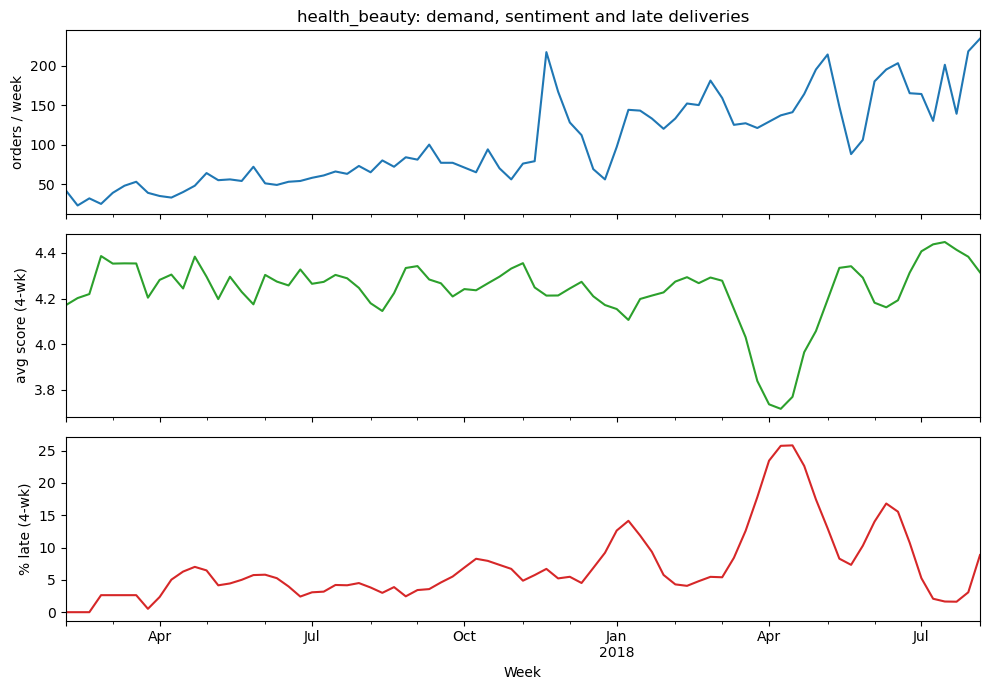

Spearman correlation between weekly late share and weekly average score (same week):
bed_bath_table          -0.62
furniture_decor         -0.55
sports_leisure          -0.54
cool_stuff              -0.53
computers_accessories   -0.52
telephony               -0.51
watches_gifts           -0.51
toys                    -0.50
garden_tools            -0.40
housewares              -0.40
health_beauty           -0.34
auto                    -0.33

Average: -0.48


In [ ]:
ex = model_table[model_table["category"] == EXAMPLE_CATEGORY].set_index("week")

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ex["orders_l0"].plot(ax=ax[0], color="tab:blue");   ax[0].set_ylabel("orders / week")
ex["sent_roll4"].plot(ax=ax[1], color="tab:green"); ax[1].set_ylabel("avg score (4-wk)")
ex["late_roll4"].mul(100).plot(ax=ax[2], color="tab:red"); ax[2].set_ylabel("% late (4-wk)")
ax[0].set_title(f"{EXAMPLE_CATEGORY}: demand, sentiment and late deliveries")
ax[2].set_xlabel("Week")
plt.tight_layout()
plt.savefig(FIGURES / "03_demand_sentiment_delay_example.png", dpi=150)
plt.show()

# same-week correlation between late share (by delivery week) and mean score (by answer week), per category
corr = {}
for cat, g in model_table.groupby("category"):
    corr[cat] = g["late_l0"].corr(g["sent_l0"], method="spearman")
corr = pd.Series(corr).sort_values()
print("Spearman correlation between weekly late share and weekly average score (same week):")
print(corr.round(2).to_string())
print(f"\nAverage: {corr.mean():.2f}")

## 6. The rolling test windows (Denes' advice)

A single train/test split is one lucky or unlucky trial. Instead we repeat the experiment on **several consecutive test windows** and report the **mean and the spread** of the errors.

How a fold works (here with `FIRST_TEST = 40`, `TEST_LEN = 4`, `STEP = 4`):
1. Test window 1 = target weeks 41-44 (positions 40-43); we may train only on what was **known before** (the 40 first weeks).
2. Window 2 = target weeks 45-48; now the training data also includes window 1 (**expanding window**).
3. Repeat until the data ends. Never shuffle, never train on the future.

**The gap for longer horizons.** When forecasting `h` weeks ahead, the outcome of week `s` is only known `h` weeks later. So a training row is allowed only if its target week is at least `h` weeks before the first test week. This is built into `split_fold()`. It stops the 4-week model from "peeking" at the weeks just before the test.

**Black Friday.** The Black Friday week (2017-11-20) falls in test window 1. No model can learn a one-off event it has never seen. So every metric is reported **with and without** that week.

In [ ]:
folds = fu.make_folds(STUDY_WEEKS, first_test=FIRST_TEST, test_len=TEST_LEN, step=STEP)
folds["black_friday_inside"] = folds.apply(
    lambda r: any((pd.Timestamp(b) >= r["test_start"]) and (pd.Timestamp(b) <= r["test_end"]) for b in fu.BLACK_FRIDAY_WEEKS), axis=1)
print(f"{len(folds)} test windows of {TEST_LEN} weeks")
folds[["fold", "test_start", "test_end", "black_friday_inside"]]

9 test windows of 4 weeks


,fold,test_start,test_end,black_friday_inside
0,1,2017-11-13,2017-12-04,True
1,2,2017-12-11,2018-01-01,False
2,3,2018-01-08,2018-01-29,False
3,4,2018-02-05,2018-02-26,False
4,5,2018-03-05,2018-03-26,False
5,6,2018-04-02,2018-04-23,False
6,7,2018-04-30,2018-05-21,False
7,8,2018-05-28,2018-06-18,False
8,9,2018-06-25,2018-07-16,False


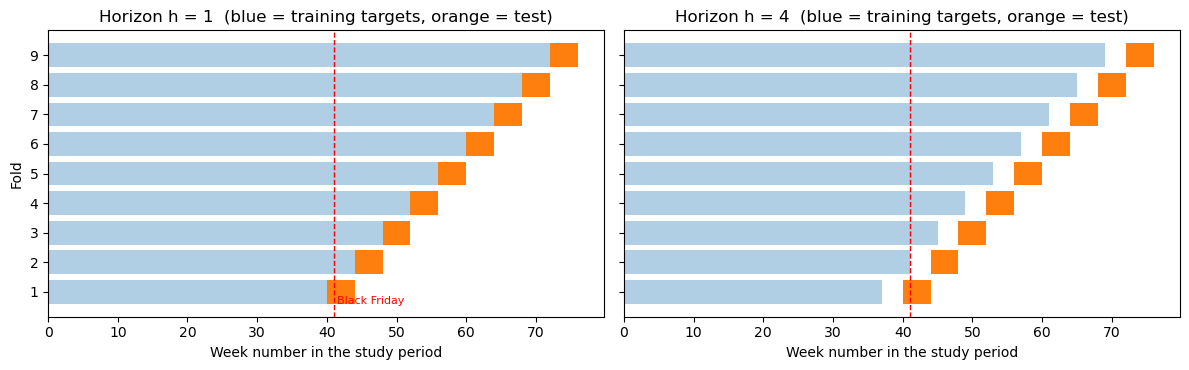

In [ ]:
# Visual: what each fold trains on (blue) and tests on (orange), for horizon 1 and horizon 4
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, h in zip(axes, [1, 4]):
    for _, f in folds.iterrows():
        train_end = f["test_start_pos"] - h              # last target position allowed in training
        ax.barh(f["fold"], train_end + 1, left=0, color="tab:blue", alpha=0.35)
        ax.barh(f["fold"], f["test_end_pos"] - f["test_start_pos"] + 1, left=f["test_start_pos"], color="tab:orange")
    for b in fu.BLACK_FRIDAY_WEEKS:
        ax.axvline(STUDY_WEEKS.get_loc(pd.Timestamp(b)), color="red", ls="--", lw=1)
    ax.set_title(f"Horizon h = {h}  (blue = training targets, orange = test)")
    ax.set_xlabel("Week number in the study period")
    ax.set_yticks(folds["fold"])
    ax.invert_yaxis()
axes[0].set_ylabel("Fold")
axes[0].text(STUDY_WEEKS.get_loc(pd.Timestamp(fu.BLACK_FRIDAY_WEEKS[0])) + 0.5, 0.6, "Black Friday", color="red", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "03_rolling_windows.png", dpi=150)
plt.show()

## 7. Baselines: the scores to beat

Two models that need **no learning at all**:

| Baseline | Forecast for week t+h | Idea |
|---|---|---|
| `naive_last_week` | orders of week `t` | "next week will look like this week" |
| `moving_avg_4w` | average orders of weeks `t-3..t` | smoother, less sensitive to one odd week |

### Metrics
- **MAE**: average error in orders per week. **RMSE**: like MAE but punishes big misses more.
- **WAPE** = total absolute error / total demand. A percentage that can be compared between small and large categories. **This is the main metric in the report.**
- **Noise floor**: even a perfect model cannot beat the randomness of counting orders. For `m` orders per week, the unavoidable error is roughly `0.8 / sqrt(m)` of demand (e.g. 100 orders -> about 8%). Any WAPE close to this is already excellent and any improvement from sentiment must be judged against how much room is left.

In [ ]:
preds = []
for h in HORIZONS:
    preds.append(fu.baseline_predictions(model_table, folds, h, "orders_l0", "naive_last_week"))
    preds.append(fu.baseline_predictions(model_table, folds, h, "orders_roll4", "moving_avg_4w"))
preds = pd.concat(preds, ignore_index=True)
print("Baseline predictions:", preds.shape)

fold_scores_all = fu.score_folds(preds)
fold_scores_noBF = fu.score_folds(preds, exclude_target_weeks=fu.BLACK_FRIDAY_WEEKS)
summary_all = fu.summarise(fold_scores_all)
summary_noBF = fu.summarise(fold_scores_noBF)

fold_scores_all.to_csv(TABLES / "03_baseline_fold_scores.csv", index=False)
summary_all.to_csv(TABLES / "03_baseline_summary.csv", index=False)
summary_noBF.to_csv(TABLES / "03_baseline_summary_no_black_friday.csv", index=False)

Baseline predictions: (2592, 7)


In [ ]:
# Overall picture: WAPE averaged over categories, mean and spread across folds
def overall(fs):
    per_fold = fs.groupby(["model", "horizon", "fold"])["WAPE"].mean().reset_index()   # mean over categories, per fold
    return per_fold.groupby(["model", "horizon"])["WAPE"].agg(["mean", "std"]).round(3)

print("WAPE, average over categories (mean and std across folds)\n")
print("INCLUDING the Black Friday week:")
print(overall(fold_scores_all).to_string())
print("\nEXCLUDING the Black Friday week:")
print(overall(fold_scores_noBF).to_string())

WAPE, average over categories (mean and std across folds)

INCLUDING the Black Friday week:
                          mean    std
model           horizon              
moving_avg_4w   1        0.294  0.158
                2        0.336  0.197
                4        0.358  0.178
naive_last_week 1        0.250  0.102
                2        0.329  0.141
                4        0.416  0.265

EXCLUDING the Black Friday week:
                          mean    std
model           horizon              
moving_avg_4w   1        0.277  0.156
                2        0.322  0.193
                4        0.346  0.173
naive_last_week 1        0.240  0.087
                2        0.327  0.139
                4        0.404  0.264


In [ ]:
# Per category, horizon 1 (excluding Black Friday): baseline WAPE vs the noise floor
h1 = summary_noBF[summary_noBF["horizon"] == 1].pivot(index="category", columns="model", values="WAPE")
volume = model_table.groupby("category")["orders_l0"].mean()
h1["avg_weekly_orders"] = volume.round(0)
h1["noise_floor"] = fu.poisson_floor(volume)
h1 = h1.sort_values("avg_weekly_orders", ascending=False)
print("WAPE at horizon 1 (excluding Black Friday week):")
h1.round(3)

WAPE at horizon 1 (excluding Black Friday week):


model,moving_avg_4w,naive_last_week,avg_weekly_orders,noise_floor
category,,,,
bed_bath_table,0.223,0.214,113.0,0.075
health_beauty,0.255,0.186,103.0,0.079
sports_leisure,0.226,0.189,91.0,0.084
computers_accessories,0.315,0.262,80.0,0.090
furniture_decor,0.322,0.260,75.0,0.092
housewares,0.238,0.220,69.0,0.096
watches_gifts,0.283,0.226,67.0,0.098
telephony,0.256,0.236,50.0,0.113
toys,0.371,0.244,46.0,0.118


In [ ]:
# Horizons side by side (excluding Black Friday)
piv = summary_noBF.pivot_table(index="category", columns=["horizon", "model"], values="WAPE").round(3)
piv = piv.loc[h1.index]
piv

horizon                           1                             2                             4                
model                 moving_avg_4w naive_last_week moving_avg_4w naive_last_week moving_avg_4w naive_last_week
category                                                                                                       
bed_bath_table                0.223           0.214         0.249           0.277         0.222           0.288
health_beauty                 0.255           0.186         0.293           0.318         0.273           0.377
sports_leisure                0.226           0.189         0.270           0.272         0.287           0.354
computers_accessories         0.315           0.262         0.377           0.356         0.422           0.447
furniture_decor               0.322           0.260         0.353           0.372         0.314           0.441
housewares                    0.238           0.220         0.281           0.291         0.277           0.347
watches_gifts                 0.283           0.226         0.321           0.323         0.338           0.398
telephony                     0.256           0.236         0.283           0.348         0.284           0.331
toys                          0.371           0.244         0.466           0.372         0.642           0.574
auto                          0.225           0.252         0.270           0.292         0.290           0.361
cool_stuff                    0.286           0.233         0.316           0.326         0.340           0.432
garden_tools                  0.323           0.363         0.387           0.379         0.458           0.492

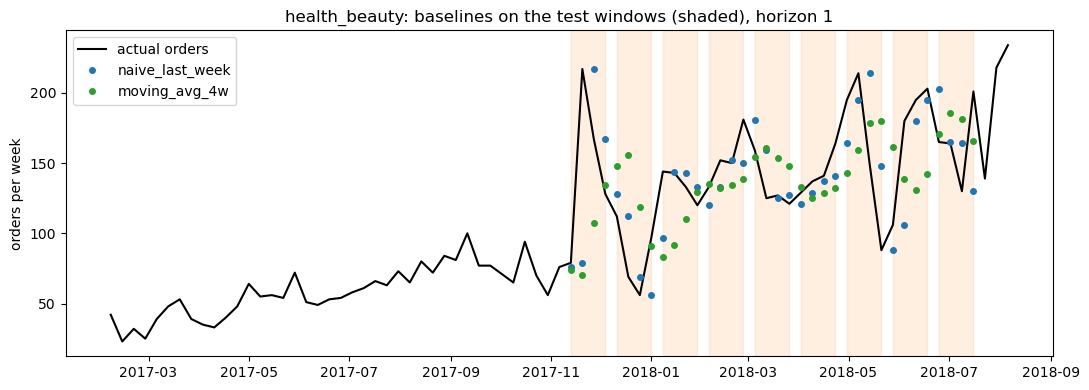

In [ ]:
# Example category: actual orders vs baseline forecasts on the test windows (horizon 1)
p = preds[(preds["category"] == EXAMPLE_CATEGORY) & (preds["horizon"] == 1)]
series = model_table[model_table["category"] == EXAMPLE_CATEGORY].set_index("week")["orders_l0"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(series.index, series.values, color="black", lw=1.5, label="actual orders")
for _, f in folds.iterrows():
    ax.axvspan(f["test_start"], f["test_end"], color="tab:orange", alpha=0.12)
for name, c in [("naive_last_week", "tab:blue"), ("moving_avg_4w", "tab:green")]:
    q = p[p["model"] == name].sort_values("target_week")
    ax.plot(q["target_week"], q["y_pred"], "o", ms=4, color=c, label=name)
ax.set_title(f"{EXAMPLE_CATEGORY}: baselines on the test windows (shaded), horizon 1")
ax.set_ylabel("orders per week"); ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "03_baselines_example.png", dpi=150)
plt.show()

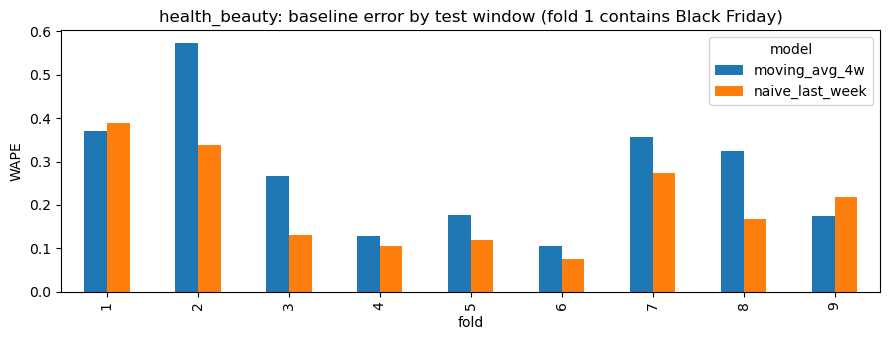

In [ ]:
# Spread across folds: how much does the error change from one test window to the next? (example category, horizon 1)
fs = fold_scores_all[(fold_scores_all["category"] == EXAMPLE_CATEGORY) & (fold_scores_all["horizon"] == 1)]
piv = fs.pivot(index="fold", columns="model", values="WAPE")
ax = piv.plot(kind="bar", figsize=(9, 3.5))
ax.set_ylabel("WAPE"); ax.set_title(f"{EXAMPLE_CATEGORY}: baseline error by test window (fold 1 contains Black Friday)")
plt.tight_layout()
plt.savefig(FIGURES / "03_baseline_error_by_fold.png", dpi=150)
plt.show()

## 8. Saving the validation setup

Notebook 04 will read this file and rebuild exactly the same folds, so that XGBoost and the baselines are compared on the same weeks.

In [ ]:
cv_config = {"first_test": FIRST_TEST, "test_len": TEST_LEN, "step": STEP, "horizons": HORIZONS,
             "black_friday_weeks": fu.BLACK_FRIDAY_WEEKS, "n_folds": int(len(folds)),
             "example_category": EXAMPLE_CATEGORY}
(PROCESSED / "cv_config.json").write_text(json.dumps(cv_config, indent=2))
print(json.dumps(cv_config, indent=2))

{
  "first_test": 40,
  "test_len": 4,
  "step": 4,
  "horizons": [
    1,
    2,
    4
  ],
  "black_friday_weeks": [
    "2017-11-20"
  ],
  "n_folds": 9,
  "example_category": "health_beauty"
}


## 9. Summary and notes for the report

**What notebook 03 delivered**
- `model_table.csv`: one row per category and week, with demand, sentiment and delay features, all placed in the week they become known, plus targets at 1, 2 and 4 weeks ahead.
- Three leakage tests, all passed (target, recomputation, truncation).
- A rolling-window design with a purge gap for longer horizons, and the Black Friday week reported separately.
- Baseline scores (naive and 4-week average) with their spread across folds, and a theoretical noise floor.

**Points to write about in the Methodology chapter (in your own words)**
- Why each signal is dated by the day it becomes known (purchase / answer / delivery) and how the truncation test shows there is no leakage.
- Why we use WAPE (comparable across categories) next to MAE and RMSE.
- Why several rolling windows instead of one split, and why the gap for longer horizons.
- Why a baseline and a noise floor are needed to judge any improvement.
- The relationship between delays and scores (section 5): sentiment partly reflects logistics, which is why model C exists.

**Next notebook (04):** XGBoost models A, B, C, D, tuned with rolling-window validation inside the training data, compared with these baselines.

*Suggested commit message:* `Add notebook 03: weekly feature table, leakage checks, rolling windows and baselines`